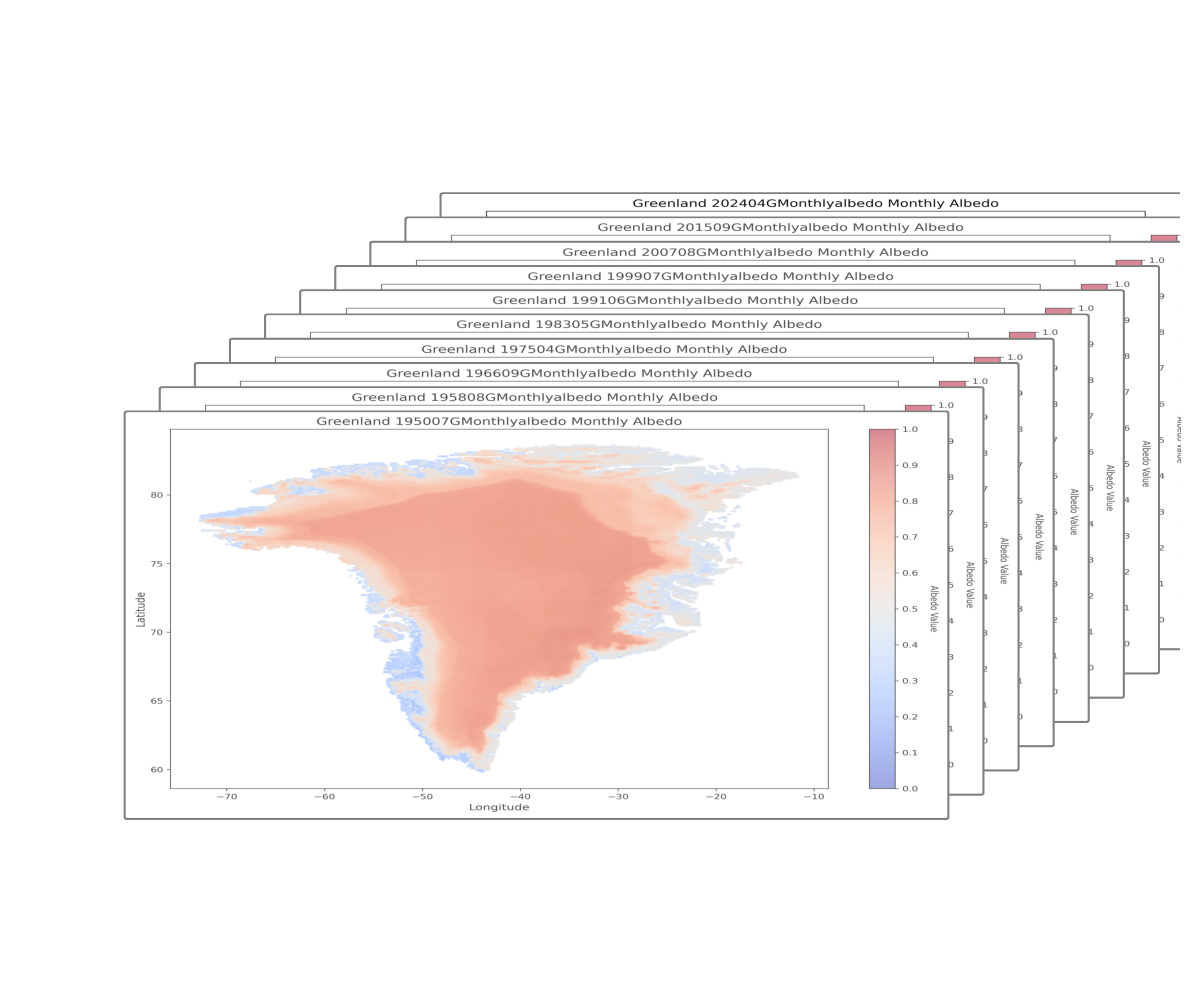

In [18]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis('off')

base_path = r"C:\greenland\1995bu\pic"
first_image = r"C:\greenland\1995bu\pic\195007GMonthlyalbedo_heatmap.png"
first_name = os.path.basename(first_image)

# 取并排序所有图片
all_files = sorted([f for f in os.listdir(base_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

# 找到首图在排序列表中的位置；找不到就当作开头
try:
    start_idx = all_files.index(first_name)
except ValueError:
    start_idx = 0

# 从首图开始，每往后数49张取一张，最多再取9张
step = 49
picks = []
for k in range(1, 10):  # 后面9张
    j = start_idx + step * k
    if j < len(all_files):
        picks.append(all_files[j])
    else:
        break

# 最终叠图序列：首图 + 按49步长挑的图
image_files = [first_name] + picks

# 叠放绘制（保持原有样式/参数；顺序改为从首图 → 更后面的图）
for i in range(9, -1, -1):
    if i < len(image_files):
        # 仅此处调整索引顺序：从首图开始往后
        idx = len(image_files) - 1 - i

        offset = (9 - i) * 0.3
        
        parallelogram = patches.FancyBboxPatch(
            (1 + offset, 2 + offset), 7, 5,
            boxstyle="round,pad=0.02",
            edgecolor='gray',
            facecolor='white',
            linewidth=1.5,
            zorder=i,
            transform=ax.transData
        )
        ax.add_patch(parallelogram)
        
        try:
            img_path = os.path.join(base_path, image_files[idx])
            img = Image.open(img_path)
            
            extent = [1 + offset, 8 + offset, 2 + offset, 7 + offset]
            ax.imshow(img, extent=extent, aspect='auto', zorder=i+0.5, alpha=0.95 if i == 0 else 0.7)
        except Exception:
            pass

plt.tight_layout()
plt.savefig(os.path.join(base_path, 'layered_images.png'), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


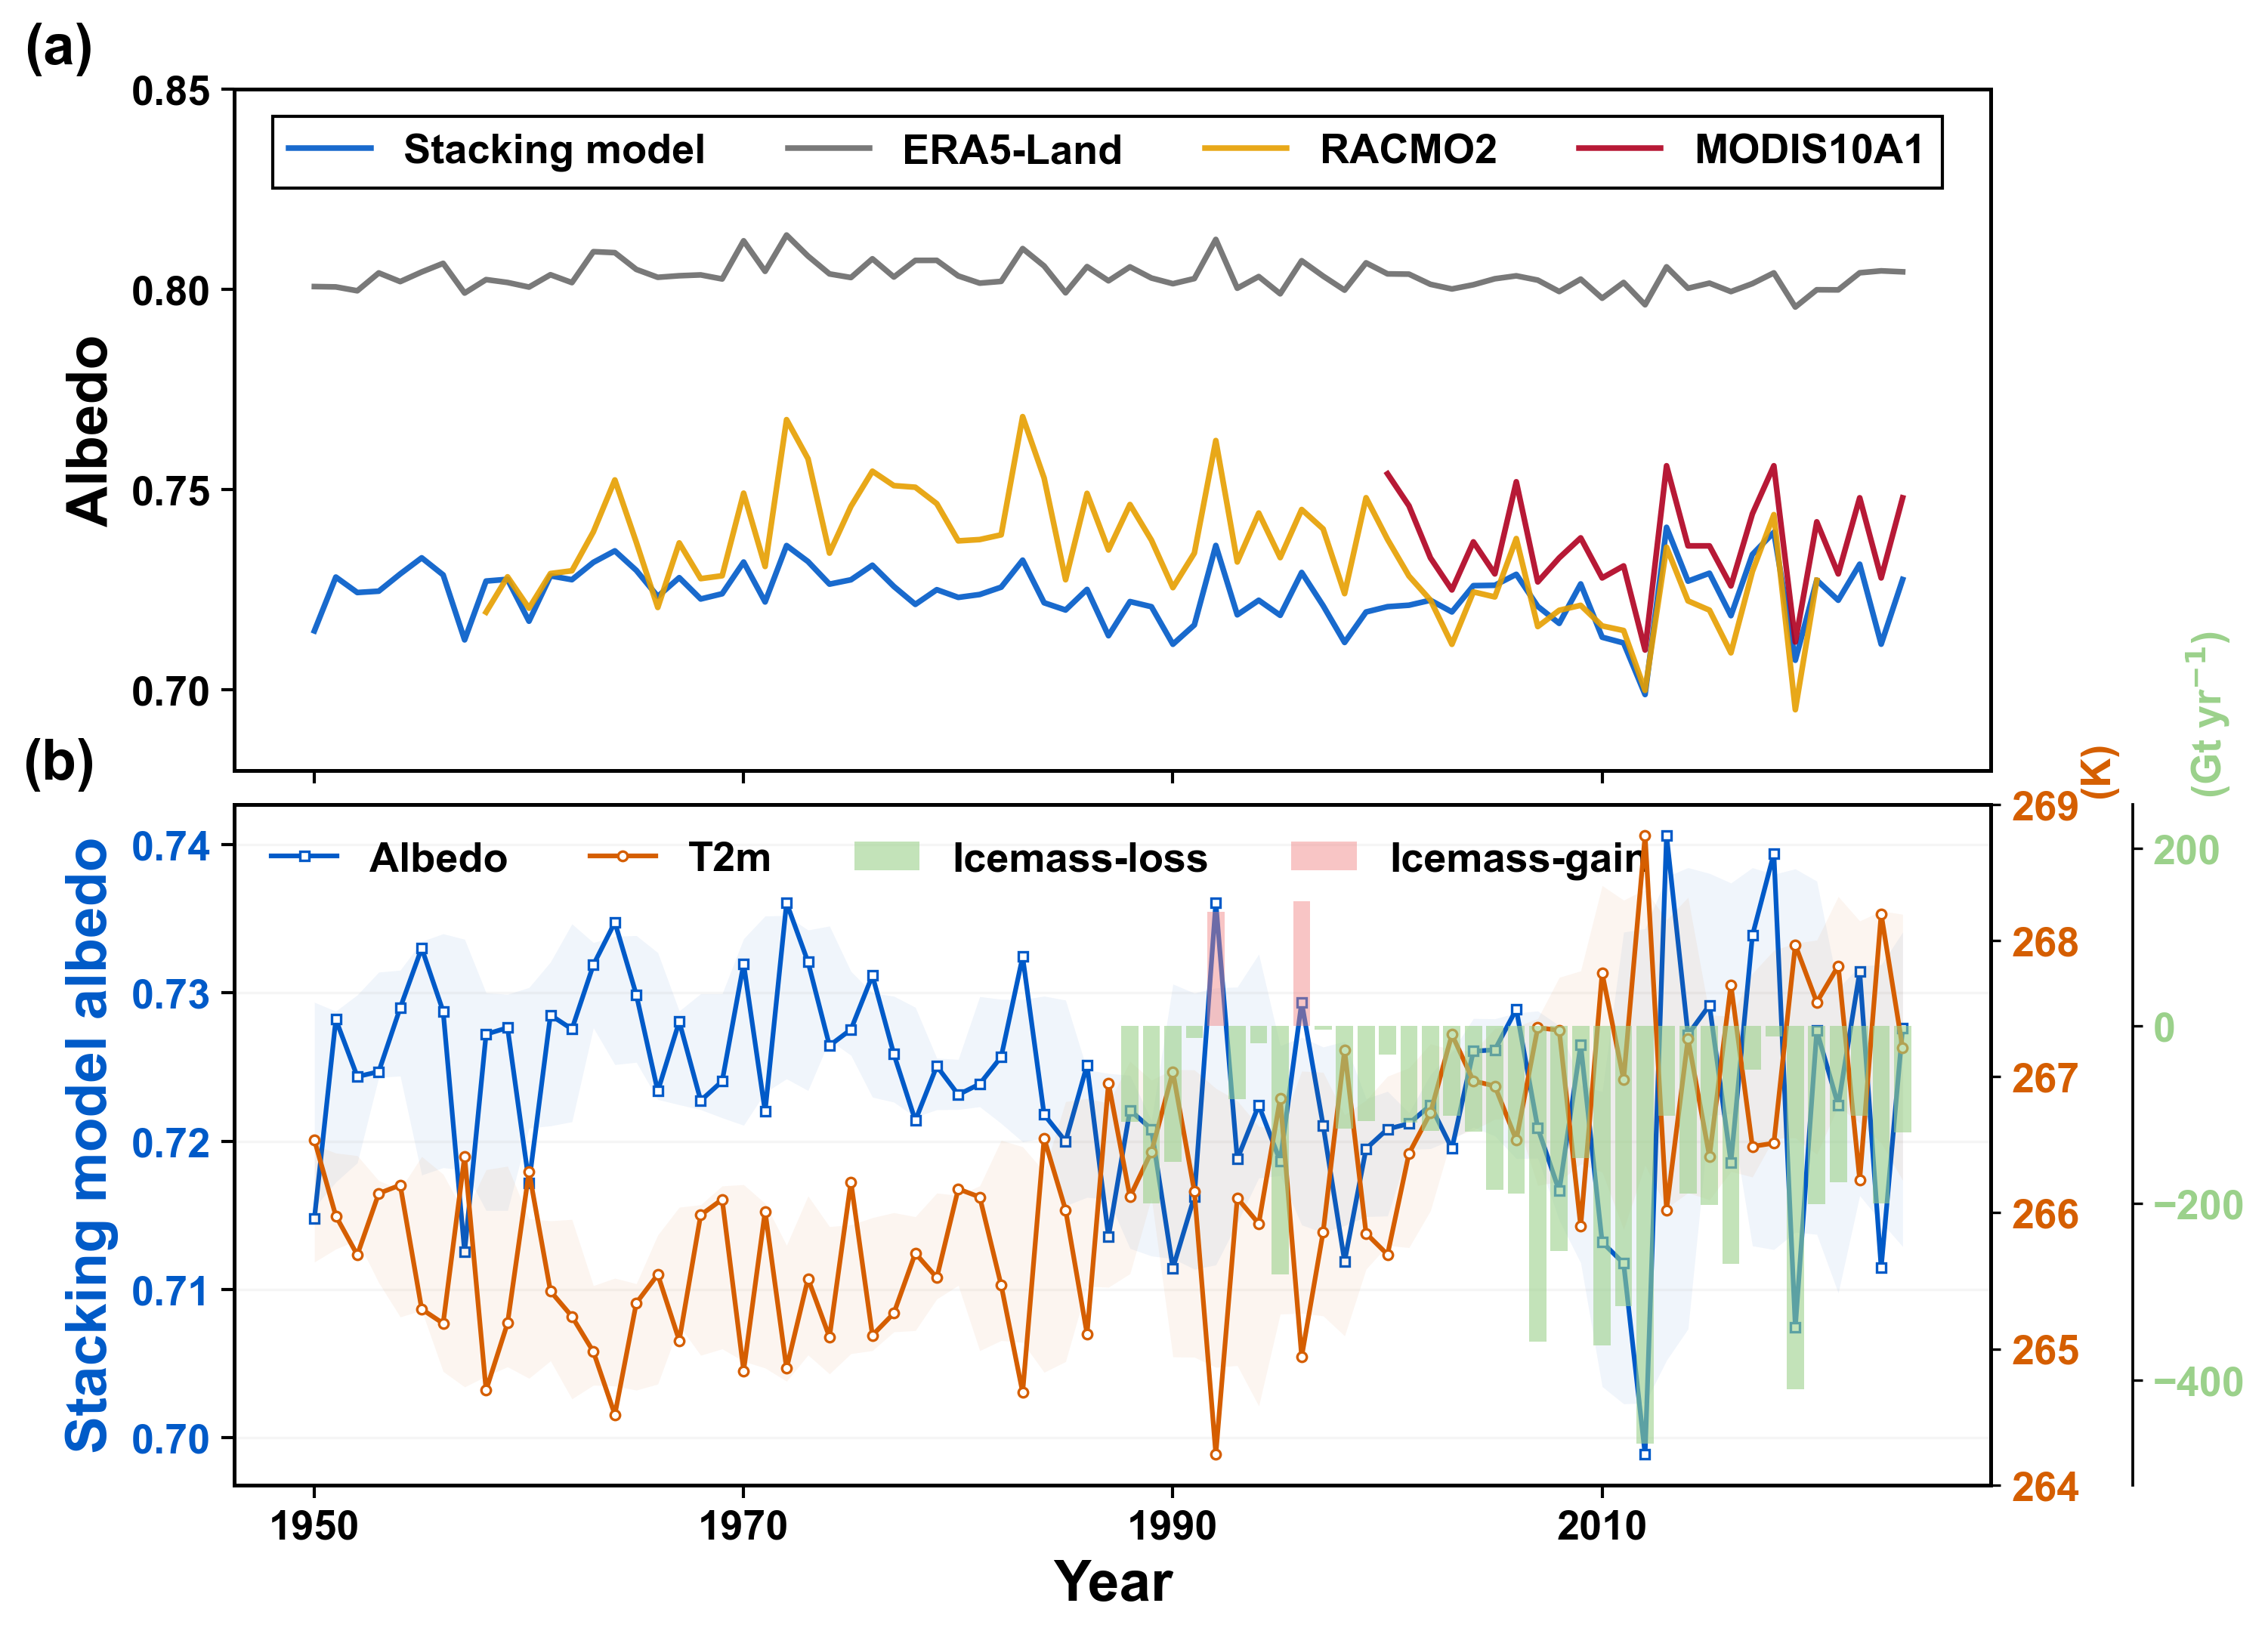

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

# === 全局字体与风格 ===
fontsize_label = 18
fontsize_tick = 13
fontsize_legend = 13

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'          # ★ 全局加粗关键 ★
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.0
plt.rcParams['ytick.major.width'] = 1.0
plt.rcParams['xtick.major.size'] = 4
plt.rcParams['ytick.major.size'] = 4
plt.rcParams['xtick.labelsize'] = fontsize_tick
plt.rcParams['ytick.labelsize'] = fontsize_tick

# ==== 数据加载 ====
try:
    df = pd.read_csv(r'C:\Users\11823\era5land\pic\era5_FAL_jja_timeseries.csv')
except FileNotFoundError:
    print("⚠️ File not found. Generating dummy data for demonstration.")
    years = np.arange(1950, 2011)
    np.random.seed(42)
    df = pd.DataFrame({
        'Year': years,
        'Stacking model': 0.72 + np.cumsum(np.random.normal(0, 0.002, len(years))) - np.linspace(0, 0.02, len(years)),
        'era5land': 0.80 + np.cumsum(np.random.normal(0, 0.003, len(years))) + np.sin(years/5) * 0.01,
        'RACMO2': 0.74 + np.cumsum(np.random.normal(0, 0.0035, len(years))) - np.cos(years/7) * 0.015,
        'MODIS10A1': 0.73 + np.cumsum(np.random.normal(0, 0.0025, len(years))) + np.sin(years/4) * 0.01,
        'ice sheet mass balance': np.random.normal(-150, 180, len(years)),
        't2m_JJA_Mean': 266 + np.random.normal(0, 0.8, len(years))
    })
    df.loc[df['Year'] < 2000, 'MODIS10A1'] = np.nan

# === 颜色配置 ===
colors = {
    'Stacking model': '#005AC8',
    'era5land': '#6A6A6A',
    'RACMO2': '#E69F00',
    'MODIS10A1': '#B00020'
}

# === 图形布局 ===
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=300, sharex=True)

# -----------------------------------
# 上图：四个反照率数据集
# -----------------------------------
data_cols = ['Stacking model', 'era5land', 'RACMO2', 'MODIS10A1']
labels = ['Stacking model', 'ERA5-Land', 'RACMO2', 'MODIS10A1']

for col, label, color in zip(data_cols, labels, colors.values()):
    ax1.plot(df['Year'], df[col], color=color, linewidth=1.8, label=label, alpha=0.9)

ax1.set_ylabel('Albedo', fontsize=fontsize_label, fontweight='bold')
ax1.set_ylim(0.68, 0.85)
ax1.set_yticks(np.arange(0.70, 0.86, 0.05))
ax1.legend(loc='upper left', bbox_to_anchor=(0.01, 0.99),
           ncol=4, frameon=True, fontsize=fontsize_legend,
           edgecolor='black', framealpha=1, fancybox=False)
ax1.grid(False)
ax1.spines['top'].set_visible(True)
ax1.spines['right'].set_visible(True)

# --- (a) ---
ax1.text(-0.1, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize_label, fontweight='bold',
         va='bottom', ha='center')

# -----------------------------------
# 下图：反照率 - 温度 - SMB
# -----------------------------------
COL_YEAR = 'Year'
COL_ALBEDO = 'Stacking model'
COL_SMB = 'ice sheet mass balance'
COL_T2M = 't2m_JJA_Mean'

LINE_WIDTH = 1.5
MARKER_SIZE = 3.0
WINDOW = 5

COLOR_T2M = "#D55E00"
COLOR_SMB_LOSS = "#9BD18B"
COLOR_SMB_GAIN = "#F08080"
COLOR_ALB = colors['Stacking model']

def rolling_band_centered(y, window=5):
    m = y.rolling(window=window, center=True, min_periods=max(2, window//2)).mean()
    s = y.rolling(window=window, center=True, min_periods=max(2, window//2)).std()
    return m - s, m + s

t2m_low, t2m_high = rolling_band_centered(df[COL_T2M], WINDOW)
alb_low, alb_high = rolling_band_centered(df[COL_ALBEDO], WINDOW)

ax = ax2
ax.fill_between(df[COL_YEAR], alb_low, alb_high, color=COLOR_ALB, alpha=0.06, lw=0)
line_alb, = ax.plot(df[COL_YEAR], df[COL_ALBEDO], '-', color=COLOR_ALB, lw=LINE_WIDTH,
                     marker='s', ms=MARKER_SIZE, markerfacecolor='white', markeredgewidth=0.8,
                     label='Albedo')
ax.set_ylabel('Stacking model albedo', color=COLOR_ALB,
              fontsize=fontsize_label, fontweight='bold')
ax.tick_params(axis='y', labelcolor=COLOR_ALB)

# ==== 右轴1：T2m ====
axr1 = ax.twinx()
axr1.fill_between(df[COL_YEAR], t2m_low, t2m_high, color=COLOR_T2M, alpha=0.06, lw=0)
line_t2m, = axr1.plot(df[COL_YEAR], df[COL_T2M], '-', color=COLOR_T2M, lw=LINE_WIDTH,
                      marker='o', ms=MARKER_SIZE, markerfacecolor='white', markeredgewidth=0.8,
                      label='T2m')
axr1.tick_params(axis='y', labelcolor=COLOR_T2M, width=0.8, length=3)
axr1.spines['right'].set_linewidth(0.9)

# ==== 右轴2：SMB ====
axr2 = ax.twinx()
axr2.spines['right'].set_position(('outward', 45))
axr2.spines['right'].set_linewidth(0.9)
axr2.tick_params(axis='y', labelcolor=COLOR_SMB_LOSS, width=0.8, length=3)

bar_loss = axr2.bar(df[COL_YEAR][df[COL_SMB] < 0], df[COL_SMB][df[COL_SMB] < 0],
                    width=0.8, color=COLOR_SMB_LOSS, alpha=0.6, label='Icemass-loss')
bar_gain = axr2.bar(df[COL_YEAR][df[COL_SMB] >= 0], df[COL_SMB][df[COL_SMB] >= 0],
                    width=0.8, color=COLOR_SMB_GAIN, alpha=0.45, label='Icemass-gain')

top_limit = max(250, df[COL_SMB].max() * 1.1)
bottom_limit = df[COL_SMB].min() * 1.1
axr2.set_ylim(top=top_limit, bottom=bottom_limit)

bottom, top = axr2.get_ylim()
start_tick = np.ceil(bottom / 200) * 200
end_tick = np.floor(top / 200) * 200
axr2.set_yticks(np.arange(start_tick, end_tick + 200, 200))

# --- 单位 ---
axr1.text(1.05, 1.01, '(K)', color=COLOR_T2M,
          fontsize=fontsize_tick, rotation='vertical',
          va='bottom', ha='left', transform=axr1.transAxes)

axr2.text(1.11, 1.01, '(Gt yr$^{-1}$)', color=COLOR_SMB_LOSS,
          fontsize=fontsize_tick, rotation='vertical',
          va='bottom', ha='left', transform=axr2.transAxes)

# --- (b) ---
ax.text(-0.1, 1.02, '(b)', transform=ax.transAxes,
        fontsize=fontsize_label, fontweight='bold',
        va='bottom', ha='center')

# ==== X 轴 ====
ax.set_xlabel('Year', fontsize=fontsize_label, fontweight='bold')
ax.set_xticks(np.arange(df[COL_YEAR].min(), df[COL_YEAR].max()+1, 20))

# ==== Legend ====
all_handles = [line_alb, line_t2m, bar_loss, bar_gain]
all_labels = [h.get_label() for h in all_handles]
ax.legend(handles=all_handles, labels=all_labels, loc='upper left',
          bbox_to_anchor=(0, 1), frameon=False, ncol=4,
          handlelength=1.6, fontsize=fontsize_legend)

ax.grid(True, axis='y', linestyle='-', alpha=0.12)
axr1.grid(False)
axr2.grid(False)

fig.subplots_adjust(hspace=0.05)

plt.show()


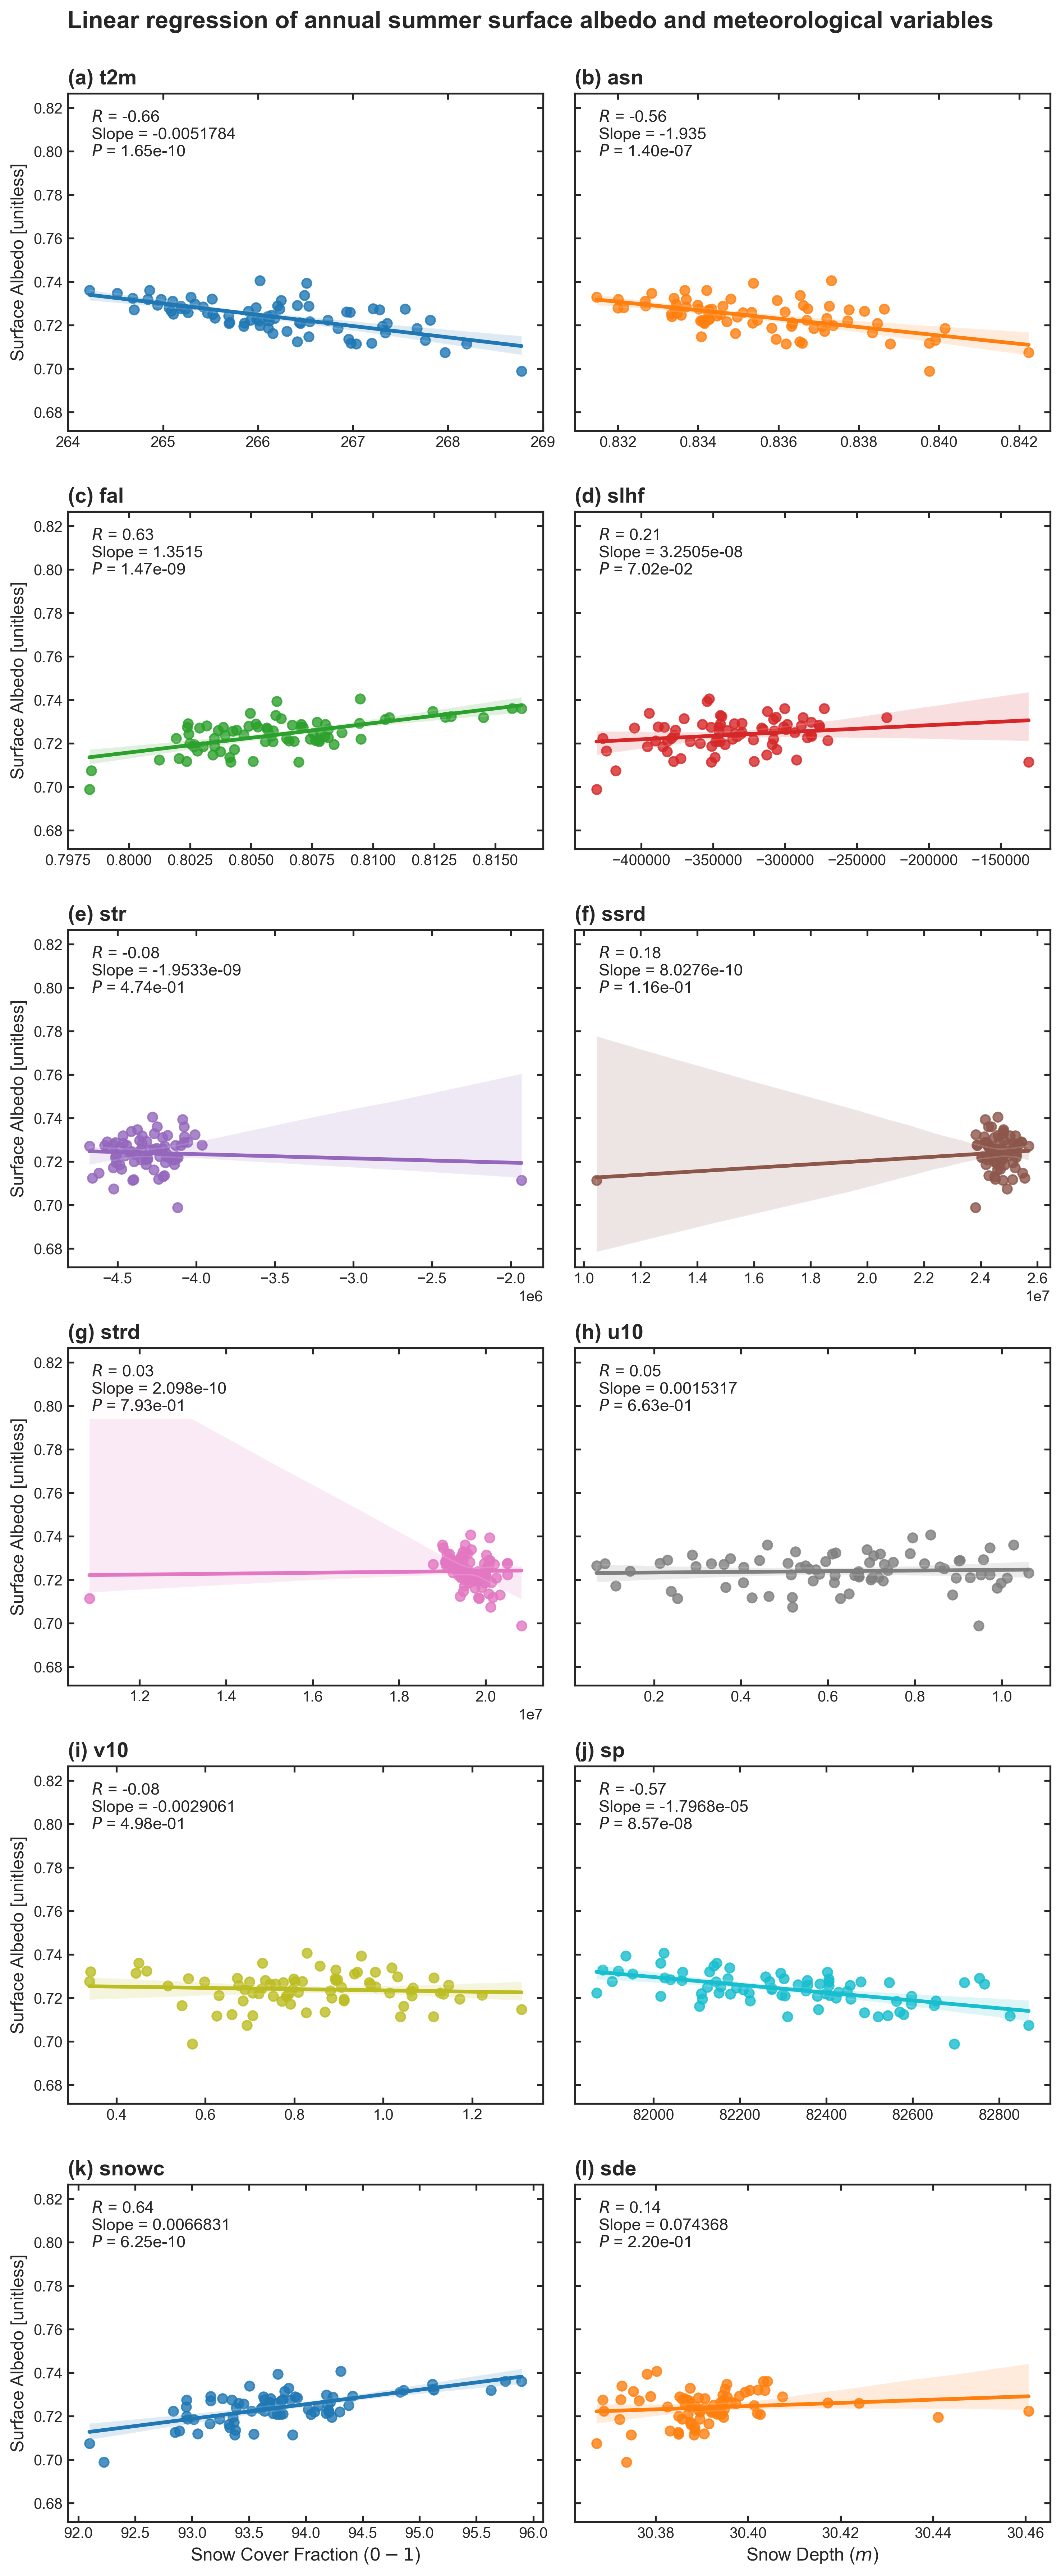

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# --- 0. 全局绘图风格和字体设置 (NPJ/Nature 风格) ---
sns.set_theme(style="ticks", rc={
    "axes.facecolor": "white", 
    "figure.facecolor": "white",
    "font.size": 12,        
    "axes.titlesize": 14,   
    "axes.labelsize": 12,   
    "xtick.labelsize": 10,  
    "ytick.labelsize": 10
})

# --- 1. 数据加载与列名定义 ---

# 替换为您的实际文件路径
file_path = "C:\\Users\\11823\\era5land\\era5_FAL_jja_timeseries.csv"

# 确定因变量 (Y) 的列名
y_col_name = 'Stacking model'

# X 变量列表 (12个变量)
x_cols = [
    't2m_JJA_Mean', 'asn_JJA_Mean', 'fal_JJA_Mean', 'slhf_JJA_Mean',
    'str_JJA_Mean', 'ssrd_JJA_Mean', 'strd_JJA_Mean', 'u10_JJA_Mean',
    'v10_JJA_Mean', 'sp_JJA_Mean', 'snowc_JJA_Mean', 'sde_JJA_Mean' 
]

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"错误：文件未找到，请检查路径：{file_path}")
    exit()

# 提取数据
y_data = df[y_col_name]
x_col_datas = df[x_cols]
n_cols = len(x_cols) 


# --- 2. 绘图设置与标签精简 ---

colors = sns.color_palette("tab10", n_colors=n_cols)

# 关键修改：调整为 6 行 2 列的布局
fig, axes = plt.subplots(
    nrows=6, # 调整为 6 行
    ncols=2, # 调整为 2 列
    figsize=(10, 24), # 调整尺寸以适应高且窄的布局
    sharey=True,
    dpi=300
)
axes = axes.flatten()

# 定义全局标签
global_y_label = "Surface Albedo [unitless]"

# X 轴标签字典
x_label_map = {
    't2m_JJA_Mean': '2m Temperature ($K$)',
    'asn_JJA_Mean': 'Snow Area Fraction', 
    'fal_JJA_Mean': 'Surface Albedo [unitless]',
    'slhf_JJA_Mean': 'Latent Heat Flux ($J\,m^{-2}$)', 
    'str_JJA_Mean': 'Net Longwave Rad. ($J\,m^{-2}$)',
    'ssrd_JJA_Mean': 'Down Shortwave Rad. ($J\,m^{-2}$)',
    'strd_JJA_Mean': 'Down Longwave Rad. ($J\,m^{-2}$)',
    'u10_JJA_Mean': '10m U Wind ($m\,s^{-1}$)', 
    'v10_JJA_Mean': '10m V Wind ($m\,s^{-1}$)',
    'sp_JJA_Mean': 'Surface Pressure ($Pa$)',
    'snowc_JJA_Mean': 'Snow Cover Fraction ($0-1$)',
    'sde_JJA_Mean': 'Snow Depth ($m$)'
}

# 提取简短的标题/列名 (t2m, asn, fal...) 
short_x_names = [col.split('_')[0] for col in x_cols]


# --- 3. 循环回归与绘图 ---

for i, x_col in enumerate(x_cols):
    
    x_data = x_col_datas[x_col]
    
    # NaN值处理
    valid_mask = ~np.isnan(x_data) & ~np.isnan(y_data)
    
    if np.sum(valid_mask) < 2:
        print(f"警告：变量 {x_col} 有效数据点不足，跳过绘图。")
        continue

    x_valid = x_data[valid_mask]
    y_valid = y_data[valid_mask]

    # 1. 执行线性回归
    slope, intercept, r_value, p_value, std_err = linregress(x_valid, y_valid)
    r = r_value
    n = len(x_valid)
    
    # 2. 绘图
    ax = axes[i]
    color = colors[i]
    
    sns.regplot(
        x=x_valid, 
        y=y_valid, 
        ax=ax,
        color=color, 
        scatter_kws={'s': 40, 'alpha': 0.8}, 
        line_kws={'lw': 2.5}, 
        ci=95
    )

    # 3. 格式化图表
    # NPJ风格标题：(a) 变量缩写
    plot_label = chr(ord('a') + i) 
    ax.set_title(
        f"({plot_label}) {short_x_names[i]}", 
        loc='left', 
        fontsize=14, 
        fontweight='bold'
    )
    
    # 轴标签
    # i % 2 == 0 确保只有每行的第一张图（左侧一列）有 Y 轴标签 (2列)
    if i % 2 == 0: 
        ax.set_ylabel(global_y_label, fontsize=12)
    else:
        ax.set_ylabel("") 
        
    # i >= 10 确保只有底行（第6行）的图有 X 轴标签 (索引 10, 11)
    if i >= 10: 
        ax.set_xlabel(x_label_map[x_col], fontsize=12)
    else:
        ax.set_xlabel("")
        
    ax.tick_params(axis='both', direction='in', top=True, right=True, length=4) 

    # 4. 添加回归统计信息到图上
    text_content = (
        f"$R$ = {r:.2f}\n" 
        f"Slope = {slope:.5g}\n"
        f"$P$ = {p_value:.2e}"
    )
    
    ax.text(
        0.05, 0.95, text_content, 
        transform=ax.transAxes, 
        fontsize=11, 
        verticalalignment='top', 
        bbox=dict(boxstyle="square,pad=0.3", fc="white", alpha=0.9, ec="none")
    )


# 5. 调整布局并保存/显示
plt.tight_layout(rect=[0, 0, 1, 0.98]) # 调整 rect 以适应高图
plt.suptitle(
    "Linear regression of annual summer surface albedo and meteorological variables",
    fontsize=16, 
    fontweight='bold', 
    y=0.995 # 标题位置调整到顶部
)

plt.show()
# plt.savefig("regression_analysis_6x2_npj_style.png", dpi=300, bbox_inches='tight')

C:\Users\11823\AppData\Local\Temp\ipykernel_47144\3216266488.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


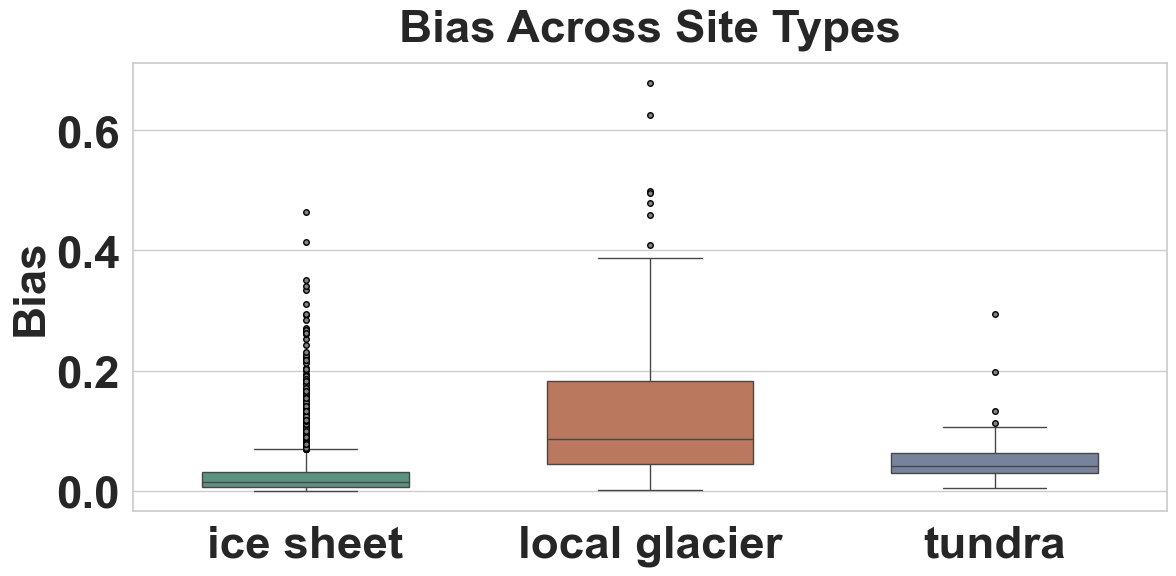

In [3]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ===== 参数区 =====
CSV_PATH = r"C:\greenland\1995bu\model&station_distance_with_type.csv"
FONT_SIZE = 33
FIG_SIZE = (12, 6)
TITLE = "Bias Across Site Types"
ROTATION = 0

# ===== 读数据 =====
df = pd.read_csv(CSV_PATH, usecols=["bias", "type"])

# ===== 绘图风格 =====
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=FIG_SIZE)

# 调色板（略暗）
palette = sns.color_palette("Set2", 3)
palette = [(r*0.8, g*0.8, b*0.8) for (r, g, b) in palette]

# 离群点
flierprops = dict(marker='o', markersize=4, markerfacecolor='grey', markeredgecolor='black')

# ===== 绘图 =====
ax = sns.boxplot(
    x="type",
    y="bias",
    data=df,
    width=0.6,
    palette=palette,
    showfliers=True,
    flierprops=flierprops
)

# ===== 美化 =====
ax.set_title(TITLE, fontsize=FONT_SIZE, pad=15, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Bias", fontsize=FONT_SIZE, fontweight="bold")

# x轴刻度（加粗 + 字号 + 水平）
ax.tick_params(axis='x', labelsize=FONT_SIZE, rotation=ROTATION)
for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")

# y轴刻度（加粗 + 字号）
ax.tick_params(axis='y', labelsize=FONT_SIZE)
for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

# ===== y轴刻度只留 “偶数刻度” =====
ymax = np.ceil(df["bias"].max() * 10) / 10
y_ticks = np.arange(0, ymax + 0.1, 0.1)

# 只保留偶数：0.0, 0.2, 0.4, 0.6, ...
even_ticks = [yt for yt in y_ticks if round(yt * 10) % 2 == 0]
ax.set_yticks(even_ticks)

plt.tight_layout()
plt.show()


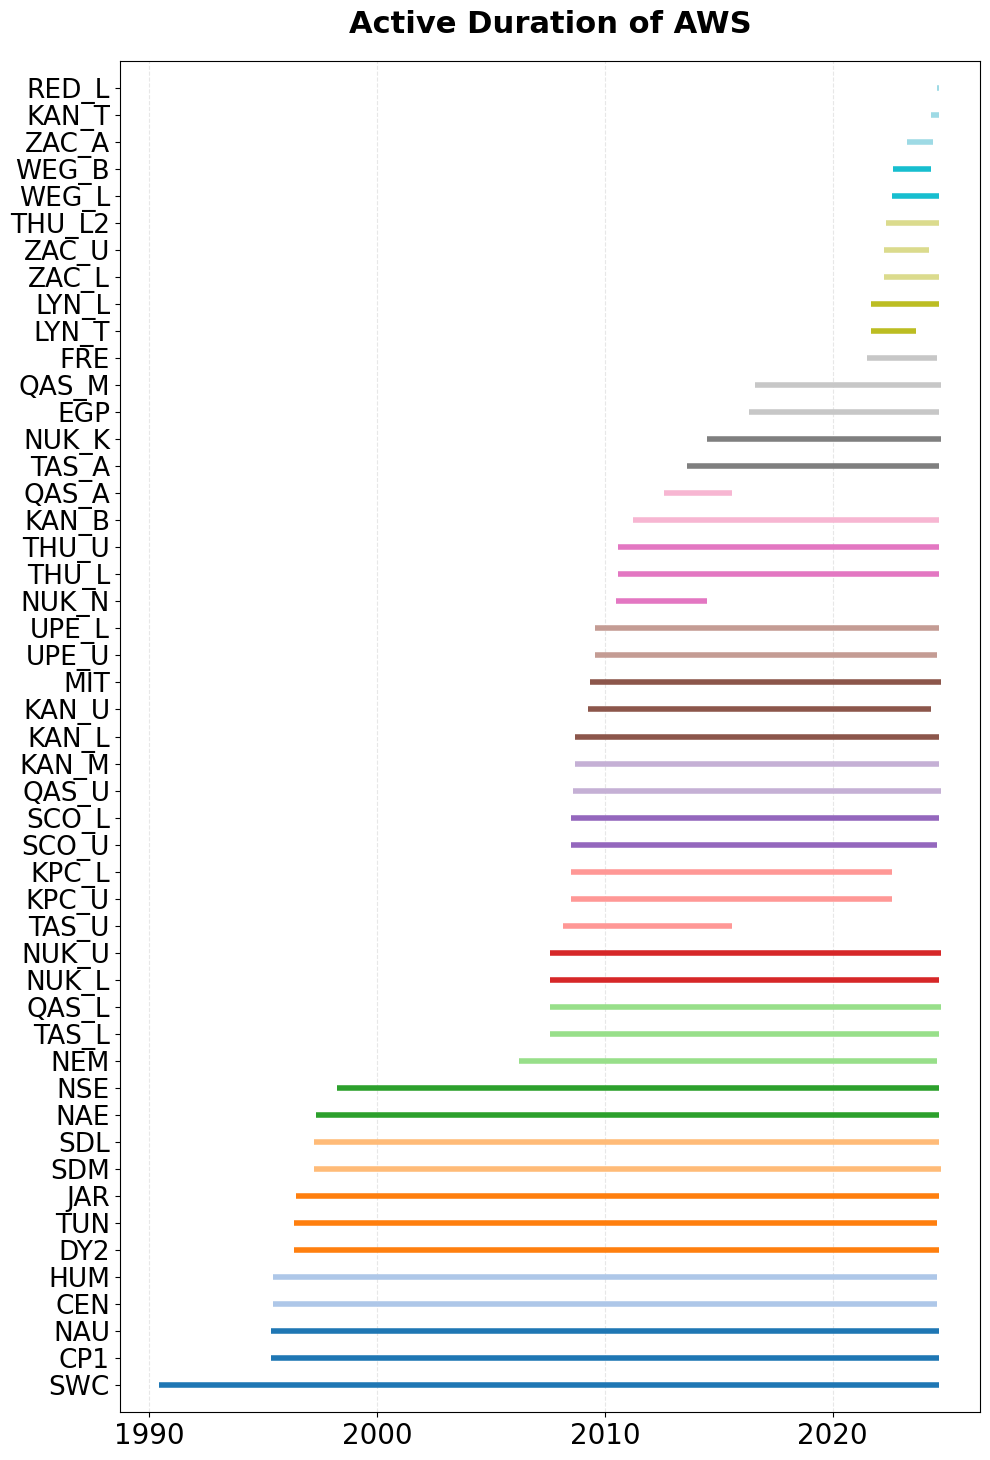

站点数据跨度统计:
SWC             | 1990-06 至 2024-09 | 34.3年 | 190个数据点
CP1             | 1995-05 至 2024-09 | 29.3年 | 162个数据点
NAU             | 1995-05 至 2024-09 | 29.3年 | 185个数据点
CEN             | 1995-06 至 2024-08 | 29.2年 | 105个数据点
HUM             | 1995-06 至 2024-08 | 29.2年 | 128个数据点
DY2             | 1996-05 至 2024-09 | 28.3年 | 214个数据点
TUN             | 1996-05 至 2024-08 | 28.3年 | 154个数据点
JAR             | 1996-06 至 2024-09 | 28.3年 | 161个数据点
SDM             | 1997-04 至 2024-10 | 27.5年 | 206个数据点
SDL             | 1997-04 至 2024-09 | 27.4年 | 200个数据点
NAE             | 1997-05 至 2024-09 | 27.3年 | 151个数据点
NSE             | 1998-04 至 2024-09 | 26.4年 | 182个数据点
NEM             | 2006-04 至 2024-08 | 18.3年 | 104个数据点
TAS_L           | 2007-08 至 2024-09 | 17.1年 | 105个数据点
QAS_L           | 2007-08 至 2024-10 | 17.2年 | 146个数据点
NUK_L           | 2007-08 至 2024-09 | 17.1年 | 120个数据点
NUK_U           | 2007-08 至 2024-10 | 17.2年 | 115个数据点
TAS_U           | 2008-03 至 2015-08 | 7.4年 | 48个数据点
KPC_U           | 20

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

# 读取CSV文件
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)

# 筛选出有albedo数据的行（非空值）
df_albedo = df[df['albedo'].notna()].copy()

# 创建日期列（假设每月1号）
df_albedo['date'] = pd.to_datetime(df_albedo['year'].astype(str) + '-' + 
                                    df_albedo['month'].astype(str) + '-01')

# 按站点分组，获取每个站点的时间跨度
station_ranges = []
for station, group in df_albedo.groupby('station'):
    min_date = group['date'].min()
    max_date = group['date'].max()
    station_ranges.append({
        'station': station,
        'start': min_date,
        'end': max_date,
        'data_points': len(group)
    })

# 转换为DataFrame并按开始时间排序
ranges_df = pd.DataFrame(station_ranges)
ranges_df = ranges_df.sort_values('start')

# 创建图形
fig, ax = plt.subplots(figsize=(10, max(8, len(ranges_df) * 0.3)))

# 绘制每个站点的时间跨度
colors = plt.cm.tab20(np.linspace(0, 1, len(ranges_df)))

for idx, (_, row) in enumerate(ranges_df.iterrows()):
    ax.plot([row['start'], row['end']], [idx, idx], 
            linewidth=4, solid_capstyle='butt', 
            color=colors[idx], label=row['station'])
    


# 设置图形属性
ax.set_ylim(-1, len(ranges_df))
ax.set_xlabel('', fontsize=16, fontweight='bold')
ax.set_ylabel('', fontsize=16, fontweight='bold')
ax.set_title('Active Duration of AWS', 
             fontsize=22, fontweight='bold', pad=20)

# 设置y轴刻度（站点名称）
ax.set_yticks(range(len(ranges_df)))
ax.set_yticklabels(ranges_df['station'].values, fontsize=19)

# 设置x轴刻度：1990-2020，每隔十年
x_ticks = pd.date_range(start='1990-01-01', end='2020-01-01', freq='10YS')
ax.set_xticks(x_ticks)
ax.set_xticklabels([date.year for date in x_ticks], fontsize=20)

# 美化网格
ax.grid(True, axis='x', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# x轴日期标签水平显示
plt.setp(ax.xaxis.get_majorticklabels(), rotation=0)

# 调整布局
plt.tight_layout()

# 显示图形
plt.show()

# 打印统计信息
print("=" * 60)
print("站点数据跨度统计:")
print("=" * 60)
for _, row in ranges_df.iterrows():
    duration = (row['end'] - row['start']).days / 365.25
    print(f"{row['station']:15s} | {row['start'].strftime('%Y-%m')} 至 "
          f"{row['end'].strftime('%Y-%m')} | "
          f"{duration:.1f}年 | {row['data_points']}个数据点")
print("=" * 60)

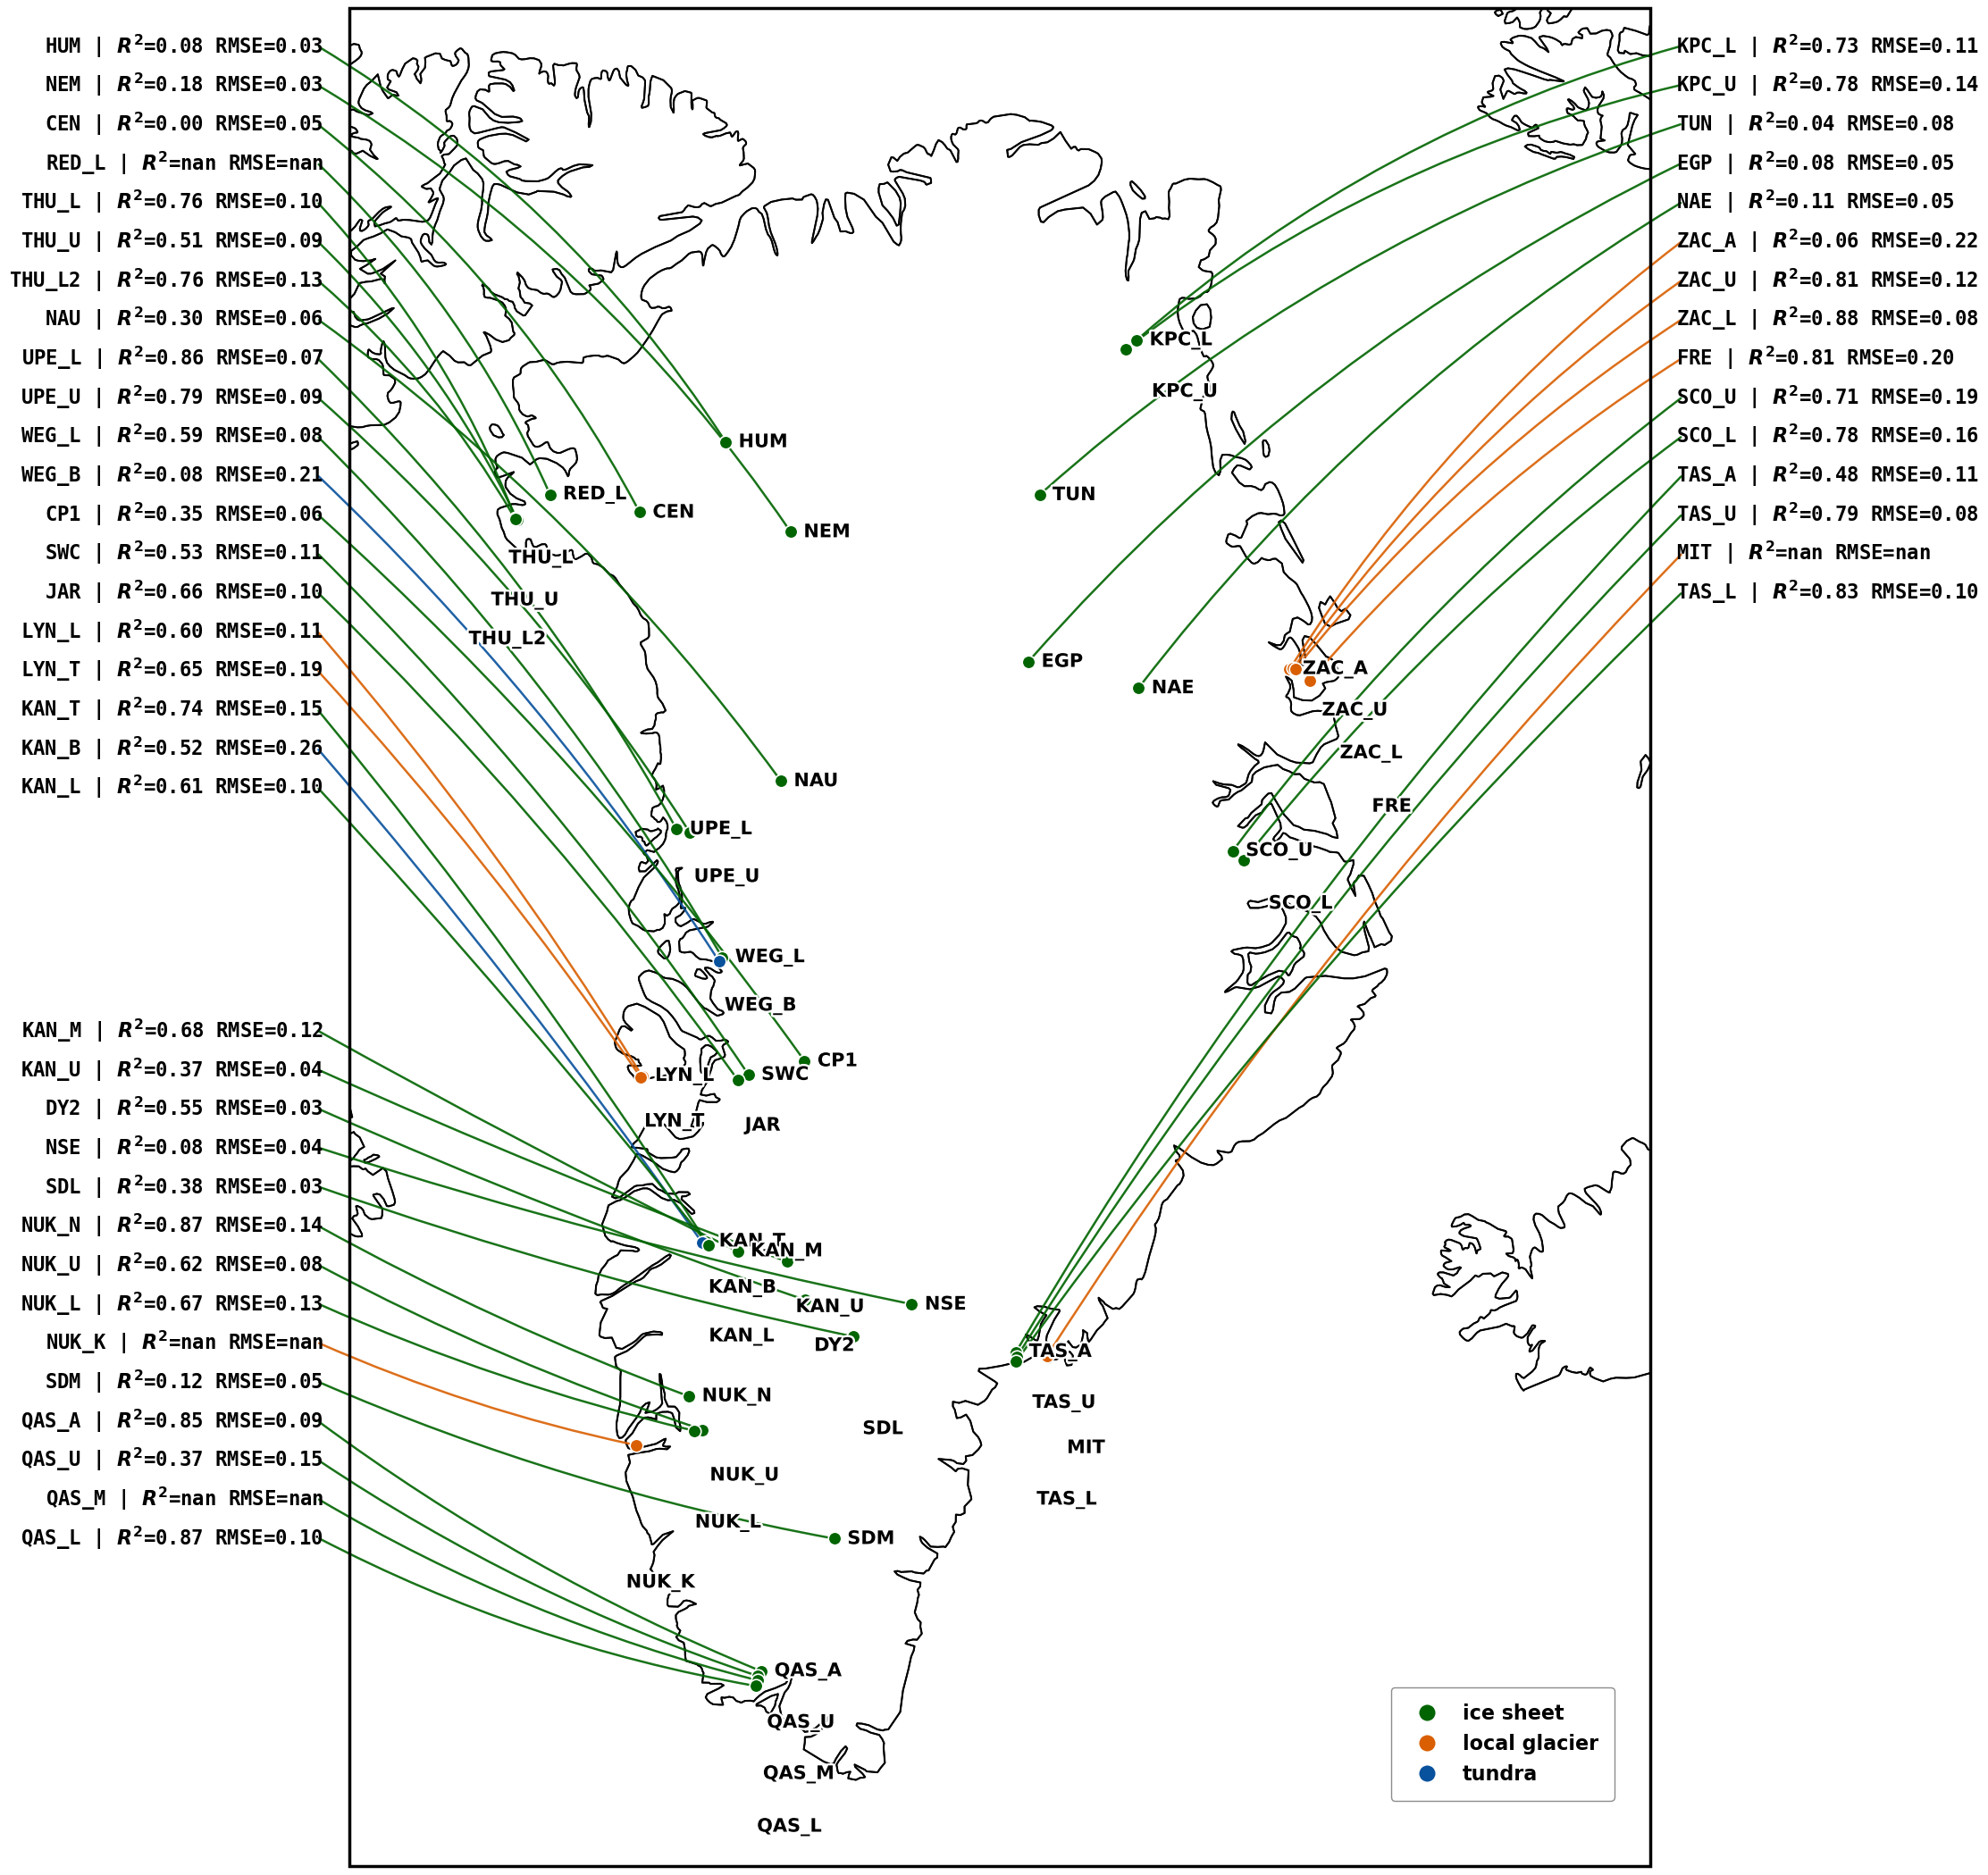

In [24]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import matplotlib.patheffects as PathEffects
from matplotlib.lines import Line2D

# ===================== 1. 数据准备 =====================
# 请确保路径正确
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\LOSO_station_performance_ALL.csv"
df = pd.read_csv(CSV_PATH)

# --- 修改1：颜色加深 (符合 npj 出版级对比度要求) ---
type_color = {
    "ice sheet": "#006400",     # Deep Forest Green (深森林绿)
    "local glacier": "#D95F02", # Burnt Orange / Dark Ochre (高对比度褐橙色)
    "tundra": "#08519C"         # Dark Azure / Royal Blue (深蓝)
}

# 排序逻辑：纬度优先
west_mask = df['longitude'] <= -42
df_west = df[west_mask].sort_values('latitude', ascending=False)
df_east = df[~west_mask].sort_values('latitude', ascending=False)

# 分组设置
nw_count = 20
sw_count = 20

# 左上组
df_nw = df_west.head(nw_count).copy()

# 左下组 (处理剩余)
if len(df_west) > nw_count:
    remaining_west = df_west.iloc[nw_count:]
    df_sw = remaining_west.sort_values('latitude', ascending=True).head(sw_count)
    df_sw = df_sw.sort_values('latitude', ascending=False)
    middle_west = remaining_west.iloc[sw_count:]
else:
    df_sw = pd.DataFrame()
    middle_west = pd.DataFrame()

# 右侧组 (东部 + 西部剩余)
df_right = pd.concat([df_east, middle_west]).sort_values('latitude', ascending=False)

# ===================== 2. 画布设置 =====================
fig = plt.figure(figsize=(26, 22)) 
proj = ccrs.NorthPolarStereo(central_longitude=-42.0)

# 调整地图位置：保持中间布局
ax = fig.add_axes([0.22, 0.02, 0.56, 0.96], projection=proj)
ax.set_extent([-57, -23, 58, 85], crs=ccrs.PlateCarree())

# 地图底图
ax.add_feature(cfeature.LAND, facecolor="white", edgecolor="black", linewidth=1.5, zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=1.2, zorder=1) # 海岸线稍微加粗一点点

# 边框加粗
ax.spines['geo'].set_linewidth(2.5)

# ===================== 3. 绘图核心逻辑 =====================

def get_adjusted_map_label_pos(lon, lat, previous_positions, min_dist=2.2):
    """
    调整避让距离。
    修改：因为字体变大了，我们将 min_dist 从 1.8 调大到 2.2，防止大字打架
    """
    y_offset = 0
    for prev_lon, prev_lat in previous_positions[-6:]:
        dist = np.sqrt((lon - prev_lon)**2 + (lat - prev_lat)**2)
        if dist < min_dist:
            if lat > prev_lat:
                y_offset += 0.65 # 避让幅度也稍微加大
            else:
                y_offset -= 0.65
    return y_offset

def plot_group(dataframe, x_anchor, y_start, row_step, align='left'):
    if dataframe.empty: return
    
    drawn_coords = []
    
    for idx, (i, row) in enumerate(zip(range(len(dataframe)), dataframe.iterrows())):
        _, d = row
        y_pos = y_start - (i * row_step)
        
        color = type_color.get(d['location_type'], 'black')
        
        # --- A. 地图点 (颜色加深) ---
        ax.scatter(d['longitude'], d['latitude'], s=110, c=color, # 点稍微加大到110
                   edgecolors='white', linewidth=1.2, transform=ccrs.PlateCarree(), zorder=5)
        
        # --- B. 地图标签 (字号加大) ---
        map_text_offset_y = get_adjusted_map_label_pos(d['longitude'], d['latitude'], drawn_coords)
        drawn_coords.append((d['longitude'], d['latitude']))
        
        # 修改：fontsize 11 -> 15
        txt = ax.text(d['longitude'], d['latitude'] + map_text_offset_y, 
                "  " + d['station'], 
                transform=ccrs.PlateCarree(),
                fontsize=15, fontweight='bold', color='black',
                va='center', ha='left', zorder=6)
        
        # 描边加粗以适应大字体
        txt.set_path_effects([PathEffects.withStroke(linewidth=3.5, foreground='white')])

        # --- C. 侧边统计表 (字号加大) ---
        stats_text = f"{d['station']} | $R^2$={d['R2']:.2f} RMSE={d['RMSE']:.2f}"
        
        if align == 'left':
            ha_text = 'right'
            line_end_x = x_anchor - 0.005 
        else:
            ha_text = 'left'
            line_end_x = x_anchor + 0.005

        # 修改：fontsize 12.5 -> 16
        ax.text(x_anchor, y_pos, stats_text, 
                transform=ax.transAxes,
                fontsize=16, ha=ha_text, va='center',
                fontfamily='monospace', fontweight='bold',
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.0))

        # --- D. 连线 (颜色加深 + 稍微加粗) ---
        norm_y = (y_pos - 0.5) * 2
        base_rad = 0.12 
        rad = -base_rad * norm_y if align == 'left' else base_rad * norm_y

        # 修改：linewidth 1.5 -> 1.8, alpha 0.8 -> 0.9 (更清晰)
        ax.annotate("",
            xy=(d['longitude'], d['latitude']),
            xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(line_end_x, y_pos),
            textcoords='axes fraction',
            arrowprops=dict(
                arrowstyle="-",
                color=color, 
                alpha=0.9, 
                linewidth=1.8, 
                connectionstyle=f"arc3,rad={rad}"
            ),
            zorder=2
        )

# ===================== 4. 执行绘制 =====================

LEFT_ANCHOR = -0.02
RIGHT_ANCHOR = 1.02
ROW_STEP = 0.021 

plot_group(df_nw, x_anchor=LEFT_ANCHOR, y_start=0.98, row_step=ROW_STEP, align='left')
plot_group(df_sw, x_anchor=LEFT_ANCHOR, y_start=0.45, row_step=ROW_STEP, align='left')
plot_group(df_right, x_anchor=RIGHT_ANCHOR, y_start=0.98, row_step=ROW_STEP, align='right')


# ===================== 5. 图例优化 (图框右下角) =====================

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=c, label=t, markersize=14)
    for t, c in type_color.items()
]

# --- 修改3：位置移动到图框右下角 (Inside Lower Right) ---
# loc='lower right' 配合 bbox_to_anchor 控制微调
# ncol=1 改为纵向排列，更适合角落
ax.legend(handles=legend_elements, 
          loc='lower right', 
          bbox_to_anchor=(0.98, 0.03), # 距离右边框和下边框各留一点空隙
          ncol=1, 
          frameon=True, # 打开边框背景，防止文字混入地图线条
          fancybox=True, # 圆角
          facecolor='white', # 白底
          framealpha=0.9,    # 不完全透明，保证遮挡背景
          edgecolor='gray',  # 灰色边框
          fontsize=16,       # 字号加大
          borderpad=0.8)

plt.show()